<p>
<img src="https://drive.google.com/uc?id=1ZHUKcwzA5c-PKUwoGmBG3TsHk6TmZ-Y0" align="left" width="250">
</p><p><h1><b><center>Mecánica Celeste</center></b></h1>
<h2><b><center>Prof. Jorge I. Zuluaga</center></b></h1>
<h2><b><center>Tarea 1</center></b><h2>
<h3><b><center>Constantes de movimiento del sistema solar</center></b><h3>
<h5><center><b>Asignada</b>: 15 de Agosto de 2023</center><h5>
<h5><center><b>Entrega</b>: 29 de Agosto de 2023</center><h5>
</p>

<hr/>
<b>Nombre</b>: Andrés Felipe Chaverra Caicedo
<br/>
<b>Cédula</b>: 1216726469
<br/>
<b>Última actualización</b>:27/08/23
<hr/>

## Enunciado

**Objetivo**: El objetivo de esta tarea es poner a prueba los resultados vistos en clase sobre las constantes en el problema de los N-cuerpos, en este caso aplicados al sistema solar.  Para ello usaremos el sistema de datos del JPL Horizons y el paquete `astroquery`.

**Procedimiento**:

Para conseguir el objetivo:

1. Obtener las masas, posiciones y velocidades de los planetas del sistema solar (8 planetas) y del Sol durante 20 años (por ejemplo entre 2000 y 2020), cada 3 meses. Use para ello Astroquery y SPICE (para las masas).

2. Para cada punto en el tiempo calcular:

   - El momentum lineal de cada cuerpo.
   - El momentum angular de cada cuerpo.
   - La energía cinética de cada cuerpo.
   - La energía potencial gravitacional de todo el sistema.

3. Usando el valor de cada una de las cantidades anteriores vamos a calcular el valor de las cuadraturas del sistema:

   - Calcular el momentum lineal total (3 cuadraturas).
   - Calcular el momentum angular total (3 cuadraturas).
   - Calcular la energía total total (1 cuadratura).

   Es muy importante tener en cuenta que el valor de cada una de las cuadraturas puede ser inmenso (las masas del sistema solar son inmensas). Por lo tanto, debemos dividir cada cuadratura por el valor característico de. para ello calcule el valor promedio del momentum lineal, angular y energía cinética del Sol.

4. Hacer gráficos de las 10 cuadraturas.

5. El momentum angular total del sistema solar define el Plano de Laplace del sistema. El momentum angular de cada uno de los cuerpos del sistema solar define la inclinación de la órbita osculatriz del cuerpo respecto al plano de Laplace. Calcular, para cada tiempo, el ángulo entre el plano de Laplace y la órbita osculatriz de cada cuerpo (incluyendo el Sol).

Ayuda: el ángulo entre dos vectores se calcula usando la propiedad del producto punto A⋅ B = A B cos θ.

6. Haga un gráfico del ángulo de la órbita osculatriz de cada cuerpo como función del tiempo.

7. Calcule el valor promedio de la inclinación orbital de cada planeta en grados respecto al plano invariante de Laplace.

**Resultados esperados**:

- Este notebook con el procedimiento debidamente comentado.

- Gráficos mínimos:
  - Gráfico de las 10 cuadraturas normalizadas (divididas por el valor para el Sol).

  - Gráfico de la inclinación de la órbita osculatriz de cada planeta y el Sol.

- Datos mínimos:
  - Valor de la inclinación orbital de cada planeta

- Gráficos opcionales:
  - Gráfico de las órbitas de los planetas.
  - Gráfico de las magnitudes del momentum lineal y angular total como función del tiempo.

- En caso de utilizar ayudas como `ChatGPT` o códigos de `Stack Over Flow` debe citar debidamente la fuente, pero también entender a cabalidad el código, el profesor puede pedir justificación.

## **Solución**

#**1)**

In [1]:
!pip install -q pymcel


In [2]:
import numpy as np
from astroquery.jplhorizons import Horizons
import matplotlib.pyplot as plt
from astropy import constants
import pandas as pd
import spiceypy as spy

In [3]:
!wget https://naif.jpl.nasa.gov/pub/naif/generic_kernels/pck/gm_de440.tpc

--2026-11-04 18:23:30--  https://naif.jpl.nasa.gov/pub/naif/generic_kernels/pck/gm_de440.tpc
Resolving naif.jpl.nasa.gov (naif.jpl.nasa.gov)... 137.79.133.14
Connecting to naif.jpl.nasa.gov (naif.jpl.nasa.gov)|137.79.133.14|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12406 (12K) [text/plain]
Saving to: ‘gm_de440.tpc’

gm_de440.tpc        100%[===================>]  12.12K  --.-KB/s    in 0s      

2026-11-04 18:23:31 (179 MB/s) - ‘gm_de440.tpc’ saved [12406/12406]



In [4]:
au=constants.au.value
m_sun=constants.M_sun.value
mearth=constants.M_earth.value
#G=constants.G.value

**UNIDADES CANÓNICAS**

In [5]:
T_canon=1/5033865 #Tiempo canónico.
D_canon=86400/5033865 #Tiempo canónico (días).
M_canon=m_sun #Masa canónica.
G=1 #Constante de gravitación universal.

In [6]:
spy.furnsh('gm_de440.tpc')
n,dato = spy.bodvrd('199','GM',1)
GM_sun = dato[0]
#GM_sun #km^3/s^2


n,dato = spy.bodvrd('10','GM',1)
GM_sun = dato[0]
#GM_sun #km^3/s^2



m=[]
for i in range(1,10): #Calculo de los GM's.
  m.append(spy.bodvrd(f'{i}99','GM',1))




In [7]:
sun= Horizons(id="10",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
mercury = Horizons(id="199",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
venus = Horizons(id="299",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
earth = Horizons(id="399",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
mars = Horizons(id="499",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
jupyter= Horizons(id="599",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
saturn= Horizons(id="699",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
uranus= Horizons(id="799",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()
neptune= Horizons(id="899",location="@0", epochs=dict(start="2000-01-01 00:00:00", stop="2020-01-01 00:00:00", step="90d")).vectors().to_pandas()


#**2)**

#**MOMENTO LINEAL**

In [8]:
#Posiciones en AU.
r_sun = np.array(sun[["x","y","z"]])
r_mer = np.array(mercury[["x","y","z"]])
r_ven = np.array(venus[["x","y","z"]])
r_earth = np.array(earth[["x","y","z"]])
r_mars = np.array(mars[["x","y","z"]])
r_jup = np.array(jupyter[["x","y","z"]])
r_sat = np.array(saturn[["x","y","z"]])
r_ura = np.array(uranus[["x","y","z"]])
r_nep = np.array(neptune[["x","y","z"]])

#Velocidades en AU/Tiempo canínoco.
v_sun = np.array(sun[["vx","vy","vz"]])/D_canon
v_mer = np.array(mercury[["vx","vy","vz"]])/D_canon
v_ven = np.array(venus[["vx","vy","vz"]])/D_canon
v_earth = np.array(earth[["vx","vy","vz"]])/D_canon
v_mars = np.array(mars[["vx","vy","vz"]])/D_canon
v_jup = np.array(jupyter[["vx","vy","vz"]])/D_canon
v_sat = np.array(saturn[["vx","vy","vz"]])/D_canon
v_ura = np.array(uranus[["vx","vy","vz"]])/D_canon
v_nep = np.array(neptune[["vx","vy","vz"]])/D_canon

#Masas en masas solares.
m_sun=1
km3_a_m3 = 1e9
m_mer=m[0][1][0]*km3_a_m3/T_canon**2
m_ven=m[1][1][0]*1e9/T_canon**2
m_earth=m[2][1][0]*1e9/T_canon**2
m_mars=m[3][1][0]*1e9/T_canon**2
m_jup=m[4][1][0]*1e9/T_canon**2
m_sat=m[5][1][0]*1e9/T_canon**2
m_ura=m[6][1][0]*1e9/T_canon**2
m_nep=m[7][1][0]*1e9/T_canon**2



M=m_sun + m_mer + m_ven + m_earth + m_mars + m_jup + m_sat + m_ura + m_nep #Masa Total del sistema.


#Tiempo
T=np.array(earth['datetime_jd'])*D_canon

#Posición del centro de masa.
R=(m_sun*r_sun + m_mer*r_mer + m_ven*r_ven + m_earth*r_earth + m_mars*r_mars + m_jup*r_jup + m_sat*r_sat + m_ura*r_ura + m_nep*r_nep)/M

#Momentos lineales.
p_sun = m_sun*v_sun
p_mer = m_mer*v_mer
p_ven = m_ven*v_ven
p_earth = m_earth*v_earth
p_mars = m_mars*v_mars
p_jup = m_jup*v_jup
p_sat = m_sat*v_sat
p_ura = m_ura*v_ura
p_nep = m_nep*v_nep

P=p_sun + p_mer + p_ven + p_earth + p_mars + p_jup + p_sat + p_ura + p_nep

#Velocidad del centro de masa.
V=(P)/M

#Momentum Lineal del centro de masa.
P_norm=np.linalg.norm(P,axis=1)

p_sun_norm=np.linalg.norm(p_sun,axis=1)

P_Cuerpo=[p_sun, p_mer, p_ven, p_earth, p_mars, p_jup, p_sat, p_ura, p_nep]
N_Cuerpo=['Sol', 'Mercurio', 'Venus', 'Tierra', 'Marte', 'Júpiter', 'Saturno', 'Urano', 'Neptuno']

P_Cuerpo_Norm=[]
for i in range(len(P_Cuerpo)):
  P_Cuerpo_Norm.append(np.linalg.norm(P_Cuerpo[i], axis=1))

df=pd.DataFrame()
df.assign(Sol = P_Cuerpo_Norm[0], Mercurio = P_Cuerpo_Norm[1], Venus = P_Cuerpo_Norm[2], \
          Tierra = P_Cuerpo_Norm[3], Marte = P_Cuerpo_Norm[4], Júpiter = P_Cuerpo_Norm[5], \
  Saturno = P_Cuerpo_Norm[6], Urano = P_Cuerpo_Norm[7], Neptuno = P_Cuerpo_Norm[8])



,Sol,Mercurio,Venus,Tierra,Marte,Júpiter,Saturno,Urano,Neptuno
0,0.000533,7.310955e+26,9.746810e+27,1.029268e+28,9.611276e+26,1.475751e+30,3.239447e+29,3.235368e+28,3.161984e+28
1,0.000531,7.302457e+26,9.636037e+27,1.013978e+28,9.073280e+26,1.471779e+30,3.245680e+29,3.233714e+28,3.162370e+28
2,0.000529,7.316711e+26,9.759123e+27,9.963089e+27,8.426978e+26,1.466704e+30,3.252436e+29,3.232161e+28,3.163381e+28
3,0.000525,7.353552e+26,9.669864e+27,1.010093e+28,8.058490e+26,1.460390e+30,3.257560e+29,3.230730e+28,3.162901e+28
4,0.000527,7.413181e+26,9.691942e+27,1.029142e+28,8.100367e+26,1.453447e+30,3.263376e+29,3.229192e+28,3.162989e+28
...,...,...,...,...,...,...,...,...,...
77,0.000471,8.553980e+26,9.768184e+27,1.028969e+28,9.301600e+26,1.369649e+30,2.955846e+29,3.244218e+28,3.181515e+28
78,0.000486,8.327906e+26,9.649113e+27,1.015642e+28,8.634797e+26,1.376592e+30,2.957143e+29,3.246214e+28,3.182483e+28
79,0.000490,8.123396e+26,9.715705e+27,9.952411e+27,8.145359e+26,1.384575e+30,2.959340e+29,3.248152e+28,3.182155e+28
80,0.000497,7.941092e+26,9.726983e+27,1.006794e+28,8.038794e+26,1.392722e+30,2.960611e+29,3.249894e+28,3.182075e+28


In [9]:
## Verificación
m_earth, m[2][1][0]*1e9/6.67e-11

(np.float64(1.010045405537596e+28), np.float64(5.976018523343668e+24))

(2e+33, 4e+33)

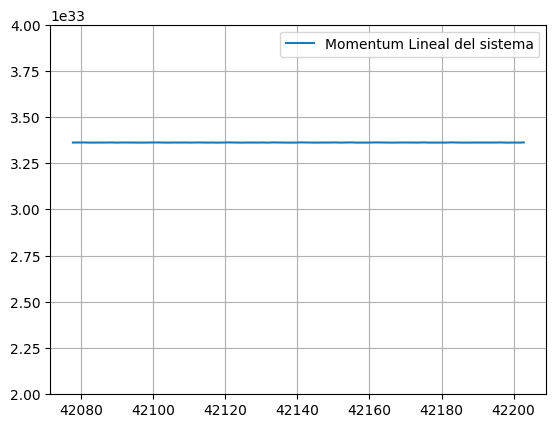

In [10]:
plt.plot(T, P_norm/p_sun_norm, label='Momentum Lineal del sistema')
#plt.scatter(T, P_norm, color='red')
#plt.axis("equal")
plt.grid()
plt.legend()
plt.ylim(2e33,4e33)

#**MOMENTO ANGULAR**

In [11]:
#Posiciones respecto al centro de masa.
r_sun_c = r_sun - R
r_mer_c = r_mer - R
r_ven_c = r_ven - R
r_earth_c = r_earth - R
r_mars_c = r_mars - R
r_jup_c = r_jup - R
r_sat_c = r_sat - R
r_ura_c = r_ura - R
r_nep_c = r_nep - R

#Velocidades respecto al centro de masa.
v_sun_c = v_sun - V
v_mer_c = v_mer - V
v_ven_c = v_ven - V
v_earth_c = v_earth - V
v_mars_c = v_mars - V
v_jup_c = v_jup - V
v_sat_c = v_sat - V
v_ura_c = v_ura - V
v_nep_c = v_nep - V



In [12]:
#Momentos angulares.

l_sun=m_sun*np.cross(r_sun,v_sun)
l_mer=m_mer*np.cross(r_mer,v_mer)
l_ven=m_ven*np.cross(r_ven,v_ven)
l_earth=m_earth*np.cross(r_earth,v_earth)
l_mars=m_mars*np.cross(r_mars,v_mars)
l_jup=m_jup*np.cross(r_jup,v_jup)
l_sat=m_sat*np.cross(r_sat,v_sat)
l_ura=m_ura*np.cross(r_ura,v_ura)
l_nep=m_nep*np.cross(r_nep,v_nep)
L=l_sun + l_mer + l_ven + l_earth + l_mars + l_jup + l_sat + l_ura + l_nep


#Momentos angulares respecto al centro de masa.

l_sun_c=m_sun*np.cross(r_sun_c,v_sun_c)
l_mer_c=m_mer*np.cross(r_mer_c,v_mer_c)
l_ven_c=m_ven*np.cross(r_ven_c,v_ven_c)
l_earth_c=m_earth*np.cross(r_earth_c,v_earth_c)
l_mars_c=m_mars*np.cross(r_mars_c,v_mars_c)
l_jup_c=m_jup*np.cross(r_jup_c,v_jup_c)
l_sat_c=m_sat*np.cross(r_sat_c,v_sat_c)
l_ura_c=m_ura*np.cross(r_ura_c,v_ura_c)
l_nep_c=m_nep*np.cross(r_nep_c,v_nep_c)

L_c = l_sun_c + l_mer_c + l_ven_c + l_earth_c + l_mars_c + l_jup_c + l_sat_c + l_ura_c + l_nep_c
L = L_c + np.cross(R,P)
L_norm=np.linalg.norm(L,axis=1)



In [13]:
L_Cuerpo=[l_sun, l_mer, l_ven, l_earth, l_mars, l_jup, l_sat, l_ura, l_nep]
N_Cuerpo=['Sol', 'Mercurio', 'Venus', 'Tierra', 'Marte', 'Júpiter', 'Saturno', 'Urano', 'Neptuno']
L_Cuerpo_Norm=[]
for i in range(len(L_Cuerpo)):
  L_Cuerpo_Norm.append(np.linalg.norm(L_Cuerpo[i], axis=1))

df=pd.DataFrame()
df.assign(Sol = L_Cuerpo_Norm[0], Mercurio = L_Cuerpo_Norm[1], Venus = L_Cuerpo_Norm[2], \
          Tierra = L_Cuerpo_Norm[3], Marte = L_Cuerpo_Norm[4], Júpiter = L_Cuerpo_Norm[5], \
  Saturno = L_Cuerpo_Norm[6], Urano = L_Cuerpo_Norm[7], Neptuno = L_Cuerpo_Norm[8])

,Sol,Mercurio,Venus,Tierra,Marte,Júpiter,Saturno,Urano,Neptuno
0,0.000004,3.444033e+26,7.089467e+27,1.010548e+28,1.329385e+27,7.315589e+30,2.970791e+30,6.442579e+29,9.523218e+29
1,0.000004,3.442235e+26,6.982231e+27,1.020072e+28,1.329594e+27,7.315873e+30,2.970581e+30,6.442440e+29,9.523602e+29
2,0.000004,3.440659e+26,6.997807e+27,1.016079e+28,1.333141e+27,7.316466e+30,2.971188e+30,6.442419e+29,9.525893e+29
3,0.000004,3.439212e+26,7.075592e+27,1.006468e+28,1.337417e+27,7.316034e+30,2.970624e+30,6.442552e+29,9.523688e+29
4,0.000003,3.437976e+26,6.948809e+27,1.007519e+28,1.341034e+27,7.317043e+30,2.971013e+30,6.442403e+29,9.523171e+29
...,...,...,...,...,...,...,...,...,...
77,0.000003,3.410476e+26,7.082138e+27,1.019782e+28,1.340376e+27,7.316803e+30,2.971494e+30,6.441914e+29,9.524004e+29
78,0.000004,3.407819e+26,6.941202e+27,1.013059e+28,1.343760e+27,7.315025e+30,2.971378e+30,6.442217e+29,9.526244e+29
79,0.000004,3.405341e+26,7.064318e+27,1.003778e+28,1.343565e+27,7.315522e+30,2.971779e+30,6.442338e+29,9.524606e+29
80,0.000004,3.402901e+26,7.021621e+27,1.008211e+28,1.340640e+27,7.314336e+30,2.970843e+30,6.442007e+29,9.523690e+29


(0.0, 1.6e+31)

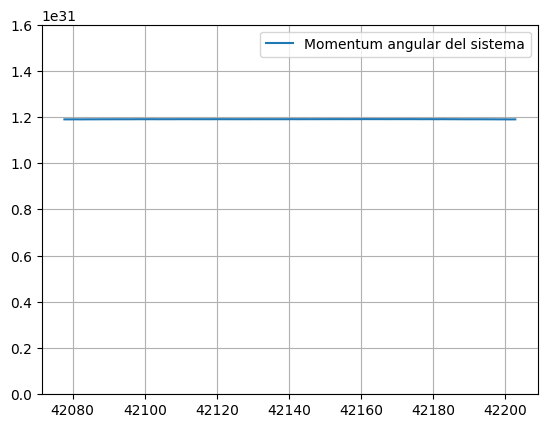

In [14]:

plt.plot(T, L_norm, label='Momentum angular del sistema')
plt.legend()
plt.grid()
plt.ylim(0,1.6e31)

#**3) y 4)**
##**CUADRATURAS**



- **Aceleración:** $$\ddot{\vec{r_i}}=-\sum_{i \neq j}\frac{\mu_j \vec{r_{ij}}}{r_{ij}}$$

- **Momento Lineal:** $$\vec{P} = \sum_i m_i\dot{\vec{r_i}}$$

- **Momento Angular:** $$\vec{L} = \sum_i m_i\vec{r_i}\times\dot{\vec{r_i}}$$

- **Energía:**

- Energìa potencial
  $$U= - \frac{1}{2} \sum_i \sum_{i \neq j}\frac{m_i \mu_i}{r_{ij}}$$


- Energía Cinética $$K= \frac{1}{2} \sum_i m_i {r_i}^{2}$$

- Energía Total
$$E= U + K$$

- **Centro de masa:**

$$\vec{R}=\frac{\sum_{i=1}^2 m_i \vec{r_i}}{\sum_{i=1}^2 m_i}$$

#Momento Lineal



(-1.5e+35, 1.5e+35)

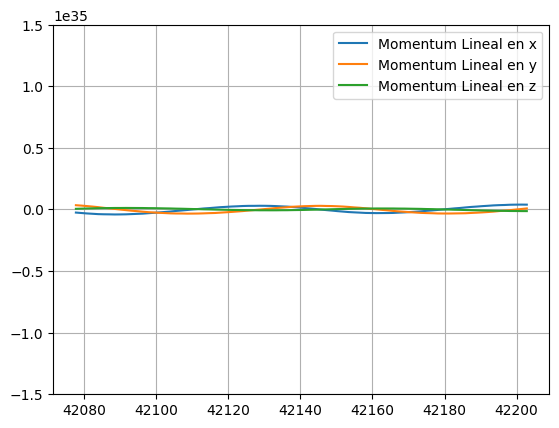

In [15]:
plt.plot(T, P[:,0]/np.mean(p_sun_norm), label='Momentum Lineal en x')
plt.plot(T, P[:,1]/np.mean(p_sun_norm), label='Momentum Lineal en y')
plt.plot(T, P[:,2]/np.mean(p_sun), label='Momentum Lineal en z')
plt.grid()
plt.legend()
plt.ylim(-1.5e35,1.5e35)


#Momento Angular



(-5e+30, 1.5e+31)

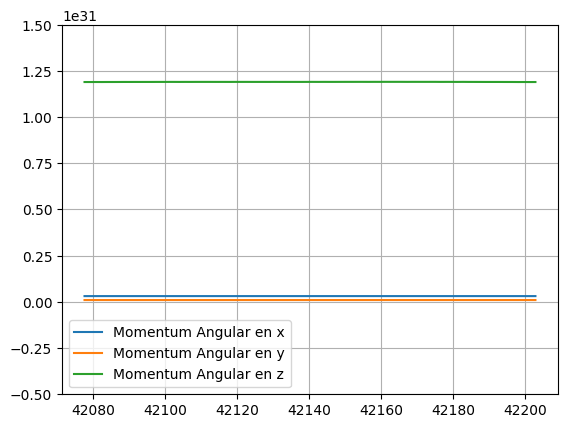

In [16]:
plt.plot(T, L[:,0], label='Momentum Angular en x')
plt.plot(T, L[:,1], label='Momentum Angular en y')
plt.plot(T, L[:,2], label='Momentum Angular en z')
plt.grid()
plt.legend()
plt.ylim(-0.5e31,1.5e31)

#Energía

In [17]:
r=[r_sun,r_mer, r_ven, r_earth, r_mars, r_jup, r_sat, r_ura, r_nep]
v=[v_sun,v_mer, v_ven, v_earth, v_mars, v_jup, v_sat, v_ura, v_nep]
m=[m_sun,m_mer, m_ven, m_earth, m_mars, m_jup, m_sat, m_ura, m_nep]

def U(m,r): #Energía potencial del sistema
  sum=0
  for i in range(len(r)):
    for j in range(len(r)):
      if i != j:
        sum+=-0.5*G*m[i]*m[j]/(np.linalg.norm(r[i][:][:]- r[j][:][:], axis=1))**3
  return(sum)

def k(m,v): #Energía Cinética de cada cuerpo.
  return  0.5*m*(np.linalg.norm(v,axis=1))**2


def K(m,v): #Energía Cinética del sistema.
  sum=0
  for i in range(len(r)):
    sum+=k(m[i],v[i])
  return(sum)

E=K(m,v) + U(m,r) #Energìa mecànica total.



In [18]:
pd.DataFrame({'Energía Potencial del sistema':U(m,r)})

,Energía Potencial del sistema
0,-3.787099e+58
1,-4.165516e+58
2,-4.377733e+58
3,-4.377345e+58
4,-4.167705e+58
...,...
77,-1.226424e+58
78,-1.413347e+58
79,-1.646382e+58
80,-1.908340e+58


In [19]:
#Energía cinética de cada cuerpo.
df=pd.DataFrame()
df.assign(Sol = k(m[0],v[0]), Mercurio = k(m[1],v[1]), Venus = k(m[2],v[2]), \
          Tierra = k(m[3],v[3]), Marte = k(m[4],v[4]), Júpiter = k(m[5],v[5]), \
          Saturno = k(m[6],v[6]), Urano = k(m[7],v[7]), Neptuno = k(m[8],v[8]))

,Sol,Mercurio,Venus,Tierra,Marte,Júpiter,Saturno,Urano,Neptuno
0,1.422533e-07,4.787004e+26,5.770288e+27,5.244286e+27,4.255959e+26,3.392053e+29,5.458985e+28,3.564836e+27,2.886298e+27
1,1.408046e-07,4.775881e+26,5.639875e+27,5.089629e+27,3.792835e+26,3.373817e+29,5.480014e+28,3.561191e+27,2.887002e+27
2,1.400262e-07,4.794544e+26,5.784876e+27,4.913796e+27,3.271741e+26,3.350591e+29,5.502852e+28,3.557771e+27,2.888850e+27
3,1.379357e-07,4.842949e+26,5.679542e+27,5.050707e+27,2.991869e+26,3.321807e+29,5.520203e+28,3.554621e+27,2.887972e+27
4,1.388079e-07,4.921809e+26,5.705506e+27,5.243003e+27,3.023045e+26,3.290295e+29,5.539932e+28,3.551237e+27,2.888132e+27
...,...,...,...,...,...,...,...,...,...
77,1.107773e-07,6.553178e+26,5.795624e+27,5.241236e+27,3.986122e+26,2.921832e+29,4.545000e+28,3.584365e+27,2.922064e+27
78,1.179017e-07,6.211366e+26,5.655192e+27,5.106350e+27,3.435102e+26,2.951530e+29,4.548987e+28,3.588775e+27,2.923842e+27
79,1.199091e-07,5.910045e+26,5.733517e+27,4.903269e+27,3.056721e+26,2.985860e+29,4.555751e+28,3.593063e+27,2.923240e+27
80,1.233524e-07,5.647757e+26,5.746836e+27,5.017770e+27,2.977262e+26,3.021102e+29,4.559664e+28,3.596916e+27,2.923092e+27


(-3e+59, 3e+59)

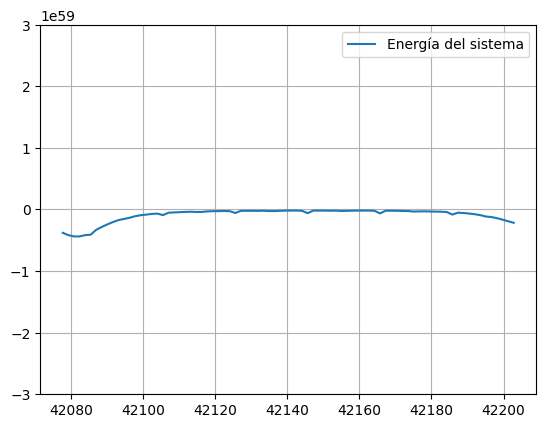

In [20]:
plt.plot(T, E, label='Energía del sistema')
#plt.xlabel()
plt.grid()
plt.legend()
plt.ylim(-3e59,3e59)


##CENTRO DE MASA

(-100.0, 100.0)

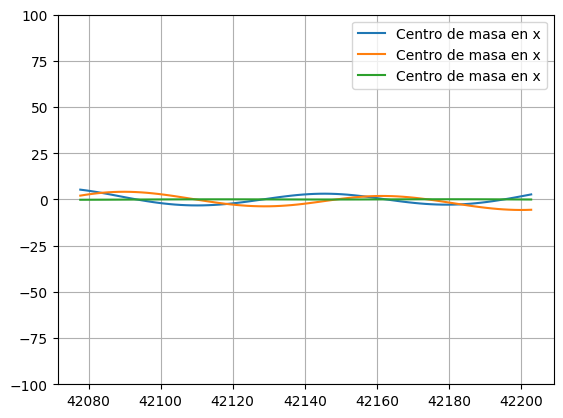

In [21]:
plt.plot(T, R[:,0], label='Centro de masa en x')
plt.plot(T, R[:,1], label='Centro de masa en x')
plt.plot(T, R[:,2], label='Centro de masa en x')
plt.grid()
plt.legend()
plt.ylim(-100,100)

#**5) PLANO INVARIANTE DE LAPLACE**

(<matplotlib.collections.PathCollection at 0x7802300e5550>, (82,))

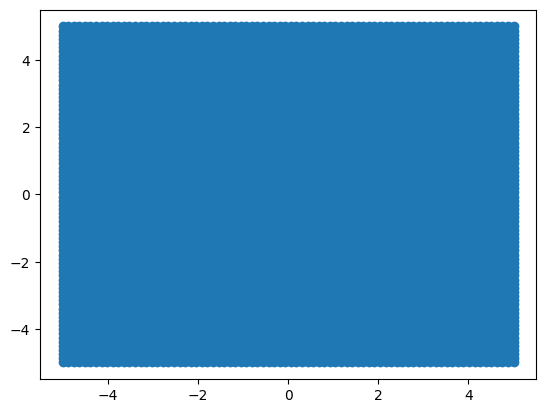

In [22]:
#Superficies 3D
x=np.linspace(-10,10,82)
y=np.linspace(-10,10,82)
a=np.arange(82)
def z(x,y,L,R): #Plano

    return -(x-np.mean(R[:,0]))*np.mean(L[:,0])-(y-np.mean(R[:,0]))*np.mean(L[:,1])

x_=np.linspace(-5,5,82)
y_=np.linspace(-5,5,82)
z_=np.zeros(len(x_))


for i in range(len(x_)):
  z_ = z(x[i],y[i],L,R)

X, Y = np.meshgrid(x_, y_) #Región
plt.scatter(X, Y), np.shape(z(x,y,L,R))

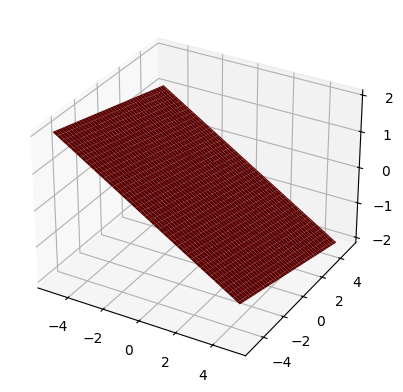

/tmp/ipykernel_664/741970540.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


In [23]:
Z=z(X,Y,L,R)
from numpy.ma.core import shape

ax = plt.axes(projection= "3d")
ax.plot_surface(X, Y, Z,color="red")
plt.show()
#plt.axis('equal')
ax.set_title('Plano invariante de Laplace')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.legend()



82

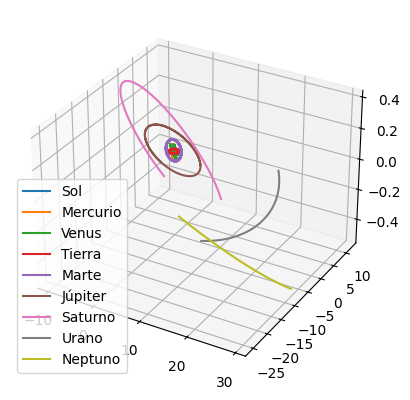

In [24]:
ax=plt.axes(projection='3d') #Órbitas de los planetas.
planetasN = ['Sol','Mercurio','Venus','Tierra','Marte','Júpiter','Saturno','Urano','Neptuno']

for i in range(len(r)):

  ax.plot(r[i][:,0],r[i][:,1],r[i][:,2],label='%s'%planetasN[i])
  ax.legend()
  #ax.plot(r_mer[:,0],r_mer[:,1],r_mer[:,2])
  #plt.axis('equal')
len(L)

#**6) y 7)**



##**ÁNGULO PARA LOS PLANETAS Y EL SOL RESPECTO AL PLANO DE LAPLACE**

$$\cos \theta = \frac{\vec{L} \cdot \vec{l_i}}{Ll_i}$$

- $\vec{L}$:  Momento angular total.

 $\vec{l_i}$:  Momento angular del planeta.

In [25]:
def ANGULO(L1,L2): #Ángulo de la órbita osculatriz.
  T=np.array(earth['datetime_jd'])
  THETA=np.arccos((L1[:,0]*L2[:,0] + L1[:,1]*L2[:,1] + L1[:,2]*L2[:,2])/(np.linalg.norm(L1,axis=1)*np.linalg.norm(L2,axis=1)))
  return np.rad2deg(THETA) #Ángulo en grados.



In [26]:
L_Cuerpo=[l_sun, l_mer, l_ven, l_earth, l_mars, l_jup, l_sat, l_ura, l_nep]
N_Cuerpo=['Sol', 'Mercurio', 'Venus', 'Tierra', 'Marte', 'Júpiter', 'Saturno', 'Urano', 'Neptuno']

df=pd.DataFrame()
df.assign(Sol = ANGULO(L,L_Cuerpo[0]), Mercurio = ANGULO(L,L_Cuerpo[1]), Venus = ANGULO(L,L_Cuerpo[2]), \
          Tierra = ANGULO(L,L_Cuerpo[3]), Marte = ANGULO(L,L_Cuerpo[4]), Júpiter = ANGULO(L,L_Cuerpo[5]), \
          Saturno = ANGULO(L,L_Cuerpo[6]), Urano = ANGULO(L,L_Cuerpo[7]), Neptuno = ANGULO(L,L_Cuerpo[8]))

,Sol,Mercurio,Venus,Tierra,Marte,Júpiter,Saturno,Urano,Neptuno
0,0.109939,6.357993,2.184519,1.580476,1.680774,0.327229,0.930522,1.028916,0.727615
1,0.103096,6.352104,2.205587,1.567042,1.682151,0.326333,0.932531,1.026821,0.724944
2,0.102774,6.346738,2.189265,1.574493,1.683767,0.326744,0.931025,1.028542,0.725904
3,0.070291,6.338054,2.196094,1.588138,1.682029,0.327257,0.930590,1.028801,0.728719
4,0.066992,6.328209,2.196702,1.579187,1.677774,0.326637,0.933189,1.027596,0.725227
...,...,...,...,...,...,...,...,...,...
77,0.172762,6.286471,2.181807,1.576595,1.673737,0.326107,0.930054,1.026943,0.723744
78,0.143454,6.295203,2.206131,1.580432,1.670865,0.327359,0.934546,1.028458,0.722989
79,0.105459,6.307915,2.196865,1.580969,1.673761,0.327851,0.932425,1.028596,0.732365
80,0.105016,6.320962,2.183898,1.576925,1.677870,0.326385,0.930331,1.027221,0.725777


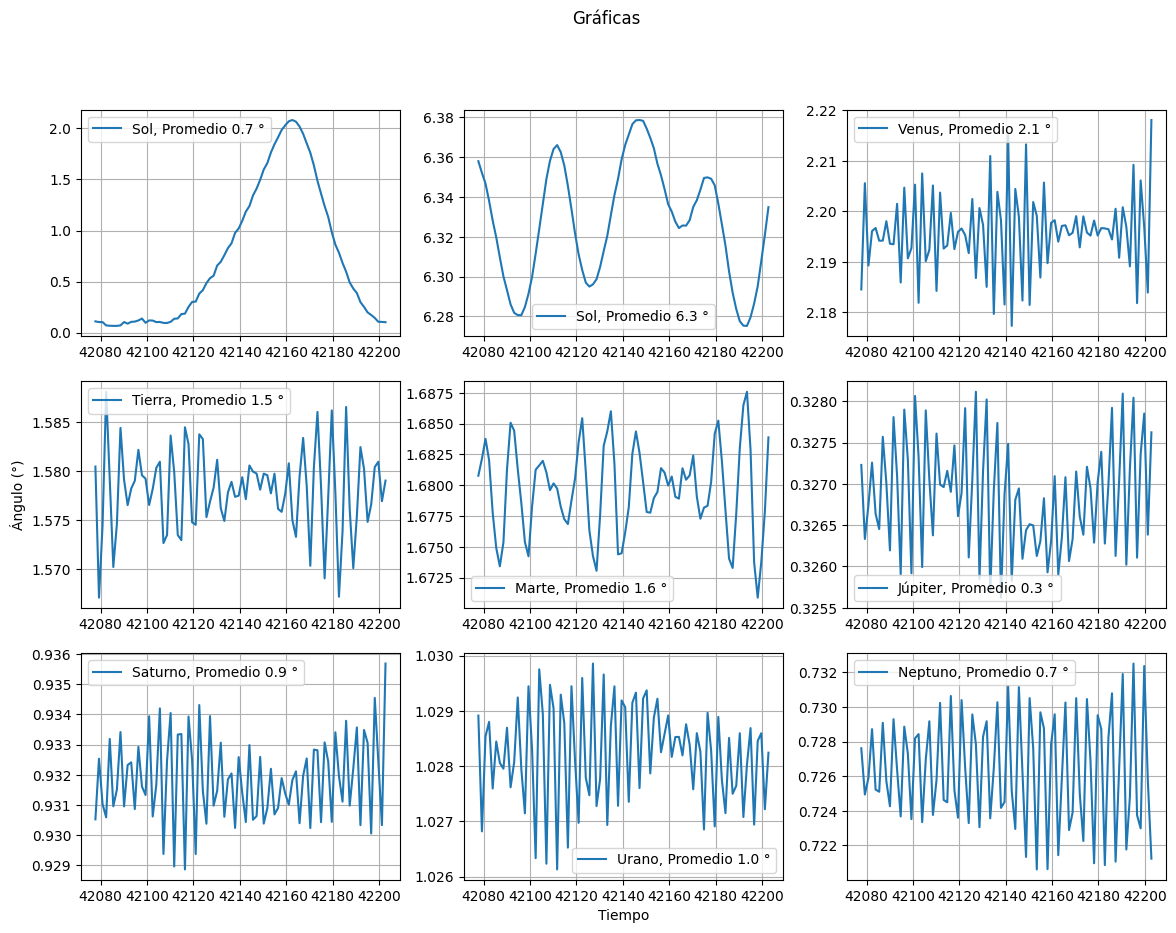

array([[<Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ángulo (°)'>, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: xlabel='Tiempo'>, <Axes: >]], dtype=object)

In [27]:
#Gráficas de los ángulos.
fig, axs = plt.subplots(3,3) #9 gráficas.
fig.set_size_inches(14,10) #Tamaño.
fig.suptitle('Gráficas')


axs[0,0].plot(T,ANGULO(L,L_Cuerpo[0]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[0],np.mean(ANGULO(L,L_Cuerpo[0])))) #En la coordenada (0,0) graficamos el momento angullar del cuerpo [0] (el Sol).
axs[0,1].plot(T,ANGULO(L,L_Cuerpo[1]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[0],np.mean(ANGULO(L,L_Cuerpo[1]))))
axs[0,2].plot(T,ANGULO(L,L_Cuerpo[2]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[2],np.mean(ANGULO(L,L_Cuerpo[2]))))
axs[1,0].plot(T,ANGULO(L,L_Cuerpo[3]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[3],np.mean(ANGULO(L,L_Cuerpo[3]))))
axs[1,1].plot(T,ANGULO(L,L_Cuerpo[4]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[4],np.mean(ANGULO(L,L_Cuerpo[4]))))
axs[1,2].plot(T,ANGULO(L,L_Cuerpo[5]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[5],np.mean(ANGULO(L,L_Cuerpo[5]))))
axs[2,0].plot(T,ANGULO(L,L_Cuerpo[6]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[6],np.mean(ANGULO(L,L_Cuerpo[6]))))
axs[2,1].plot(T,ANGULO(L,L_Cuerpo[7]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[7],np.mean(ANGULO(L,L_Cuerpo[7]))))
axs[2,2].plot(T,ANGULO(L,L_Cuerpo[8]), \
              label='%s, Promedio %.3s °'%(N_Cuerpo[8],np.mean(ANGULO(L,L_Cuerpo[8]))))


for i in range(3):
  for j in range(3):
    axs[i,j].grid()
    axs[i,j].legend()


axs[2,1].set_xlabel('Tiempo')
axs[1,0].set_ylabel('Ángulo (°)')


plt.show()
axs


#**Conclusiones**

- La energía del sistema (en el rango de 20 años), es negativa, lo cual indica que el sistema está ligado.

- El ángulo de los planetas al tener variaciones de centésimas o milésimas, se puede concluir que es constante. Lo mismo aplica para el momento angular.

- El momento lineal al tener altas variaciones, es necesario convertir las unidades MKS a unidades canónicas para normalizar entre el momento lineal del Sol.
